<a href="https://colab.research.google.com/github/Lakshman0707/Campus-AI-Pulse-2026/blob/main/LAKSHMAN_J(20241CSE0620).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    roc_curve,
    roc_auc_score
)

from sklearn.preprocessing import label_binarize

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import files
import pandas as pd

# Upload dataset
uploaded = files.upload()

# Load CSV file
file_name = "campus_ai_pulse_2026.csv"

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")

display(df.head())

print("\nDataset shape:", df.shape)

print("\nTarget values:")
print(df["ai_dependency_level"].value_counts())

Saving campus_ai_pulse_2026.csv to campus_ai_pulse_2026.csv
Dataset loaded successfully!


,student_id,age,gender,country,university_type,program,year_of_study,uni_ai_policy,uses_ai,primary_ai_tool,...,ai_assignment_share_pct,study_hours_per_week,cgpa,critical_thinking_score,time_saved_pct,ai_dependency_score,ai_dependency_level,integrity_concern_level,flagged_by_ai_detector,would_recommend_ai
0,S0001,20,Female,India,Public,Engineering,2,Allowed,Yes,ChatGPT,...,51,13.7,2.88,53,47,8,High,3,Yes,No
1,S0002,22,Male,Nigeria,Private,Computer Science,2,No clear policy,Yes,ChatGPT,...,11,19.8,3.52,84,29,2,Low,3,No,Yes
2,S0003,21,Male,United States,Private,Business,4,Allowed with disclosure,Yes,Perplexity,...,11,20.4,2.94,72,20,2,Low,3,No,Yes
3,S0004,22,Female,Bangladesh,Private,Medicine & Health,3,No clear policy,Yes,Claude,...,46,18.0,2.70,68,23,6,Medium,1,No,Yes
4,S0005,20,Male,Bangladesh,Private,Natural Sciences,1,Allowed,Yes,ChatGPT,...,9,24.8,3.01,62,19,3,Low,1,No,No



Dataset shape: (1200, 24)

Target values:
ai_dependency_level
Low       525
Medium    435
High      240
Name: count, dtype: int64


In [ ]:
# Remove student ID and target-related score
X = df.drop(
    columns=["student_id", "ai_dependency_level", "ai_dependency_score"]
)

# Target variable
y = df["ai_dependency_level"]

print("Input features (X):")
display(X.head())

print("\nTarget variable (y):")
display(y.head())

print("\nNumber of input features:", X.shape[1])
print("Number of target values:", y.shape[0])

print("\nTarget distribution:")
print(y.value_counts())

Input features (X):


,age,gender,country,university_type,program,year_of_study,uni_ai_policy,uses_ai,primary_ai_tool,primary_use_case,...,paid_ai_subscription,prompt_skill_level,ai_assignment_share_pct,study_hours_per_week,cgpa,critical_thinking_score,time_saved_pct,integrity_concern_level,flagged_by_ai_detector,would_recommend_ai
0,20,Female,India,Public,Engineering,2,Allowed,Yes,ChatGPT,Research & Summaries,...,No,4,51,13.7,2.88,53,47,3,Yes,No
1,22,Male,Nigeria,Private,Computer Science,2,No clear policy,Yes,ChatGPT,Research & Summaries,...,No,3,11,19.8,3.52,84,29,3,No,Yes
2,21,Male,United States,Private,Business,4,Allowed with disclosure,Yes,Perplexity,Coding Help,...,No,3,11,20.4,2.94,72,20,3,No,Yes
3,22,Female,Bangladesh,Private,Medicine & Health,3,No clear policy,Yes,Claude,Exam Prep,...,No,3,46,18.0,2.70,68,23,1,No,Yes
4,20,Male,Bangladesh,Private,Natural Sciences,1,Allowed,Yes,ChatGPT,Writing & Editing,...,No,2,9,24.8,3.01,62,19,1,No,No



Target variable (y):


,ai_dependency_level
0,High
1,Low
2,Low
3,Medium
4,Low



Number of input features: 21
Number of target values: 1200

Target distribution:
ai_dependency_level
Low       525
Medium    435
High      240
Name: count, dtype: int64


In [ ]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   student_id               1200 non-null   object 
 1   age                      1200 non-null   int64  
 2   gender                   1200 non-null   object 
 3   country                  1200 non-null   object 
 4   university_type          1200 non-null   object 
 5   program                  1200 non-null   object 
 6   year_of_study            1200 non-null   int64  
 7   uni_ai_policy            1200 non-null   object 
 8   uses_ai                  1200 non-null   object 
 9   primary_ai_tool          1200 non-null   object 
 10  primary_use_case         1200 non-null   object 
 11  ai_hours_per_week        1200 non-null   float64
 12  paid_ai_subscription     1200 non-null   object 
 13  prompt_skill_level       1200 non-null   int64  
 14  ai_

,age,year_of_study,ai_hours_per_week,prompt_skill_level,ai_assignment_share_pct,study_hours_per_week,cgpa,critical_thinking_score,time_saved_pct,ai_dependency_score,integrity_concern_level
count,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000
mean,20.115833,2.286667,5.882417,2.485833,25.779167,17.700333,3.040325,61.670000,21.722500,4.220000,3.079167
std,1.433805,1.085728,4.604273,1.233315,17.892797,4.322299,0.377610,11.473991,12.767981,2.619921,1.053007
min,18.000000,1.000000,0.000000,0.000000,0.000000,3.400000,1.870000,28.000000,0.000000,1.000000,1.000000
25%,19.000000,1.000000,2.600000,2.000000,13.000000,14.700000,2.790000,54.000000,14.000000,2.000000,2.000000
50%,20.000000,2.000000,5.150000,3.000000,25.000000,17.650000,3.030000,61.000000,23.000000,4.000000,3.000000
75%,21.000000,3.000000,8.300000,3.000000,36.250000,20.800000,3.300000,70.000000,30.000000,6.000000,4.000000
max,24.000000,4.000000,31.600000,5.000000,99.000000,33.200000,4.000000,100.000000,64.000000,10.000000,5.000000


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training samples: 960
Testing samples: 240

Training data shape: (960, 21)
Testing data shape: (240, 21)


In [ ]:
# Identify numerical and categorical columns

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

# Numerical data processing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical data processing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both transformations
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Create the machine learning pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=5000))
])

model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [ ]:
y_pred = model.predict(X_test)

print("Actual values:")
print(y_test.values[:10])

print("\nPredicted values:")
print(y_pred[:10])

Actual values:
['Low' 'Medium' 'Medium' 'Low' 'High' 'Low' 'Low' 'Low' 'Medium' 'Low']

Predicted values:
['Low' 'Low' 'Medium' 'Low' 'Medium' 'Low' 'Low' 'Low' 'Medium' 'Low']


In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Low", "Medium", "High"]
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[84 20  1]
 [26 45 16]
 [ 4 17 27]]


In [ ]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average="weighted"
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted"
)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted"
)

print("MODEL EVALUATION METRICS")

print("Accuracy:", round(accuracy * 100, 2), "%")

print("Precision:", round(precision * 100, 2), "%")

print("Recall:", round(recall * 100, 2), "%")

print("F1-Score:", round(f1 * 100, 2), "%")

MODEL EVALUATION METRICS
Accuracy: 65.0 %
Precision: 64.4 %
Recall: 65.0 %
F1-Score: 64.61 %


In [ ]:
print(
    classification_report(
        y_test,
        y_pred,
        labels=["Low", "Medium", "High"]
    )
)

              precision    recall  f1-score   support

         Low       0.74      0.80      0.77       105
      Medium       0.55      0.52      0.53        87
        High       0.61      0.56      0.59        48

    accuracy                           0.65       240
   macro avg       0.63      0.63      0.63       240
weighted avg       0.64      0.65      0.65       240



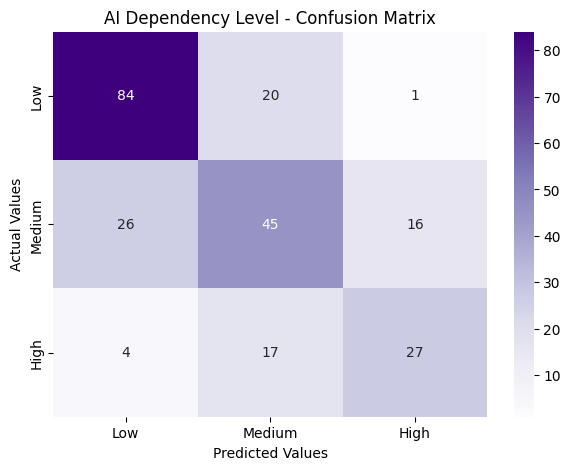

In [ ]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.title("AI Dependency Level - Confusion Matrix")

plt.show()

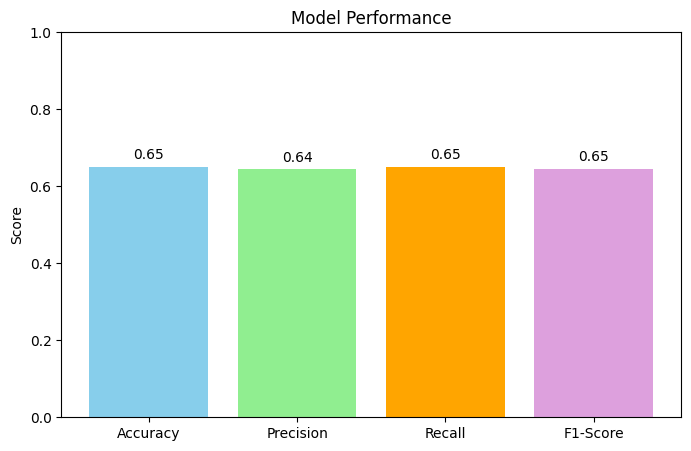

In [ ]:
metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1
}

plt.figure(figsize=(8, 5))

plt.bar(
    metrics.keys(),
    metrics.values(),
    color=["skyblue", "lightgreen", "orange", "plum"]
)

plt.ylim(0, 1)

plt.ylabel("Score")

plt.title("Model Performance")

for i, value in enumerate(metrics.values()):
    plt.text(
        i,
        value + 0.02,
        f"{value:.2f}",
        ha="center"
    )

plt.show()

/tmp/ipykernel_2890/4184156287.py:12: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  comparison_numeric = comparison.replace(class_mapping)


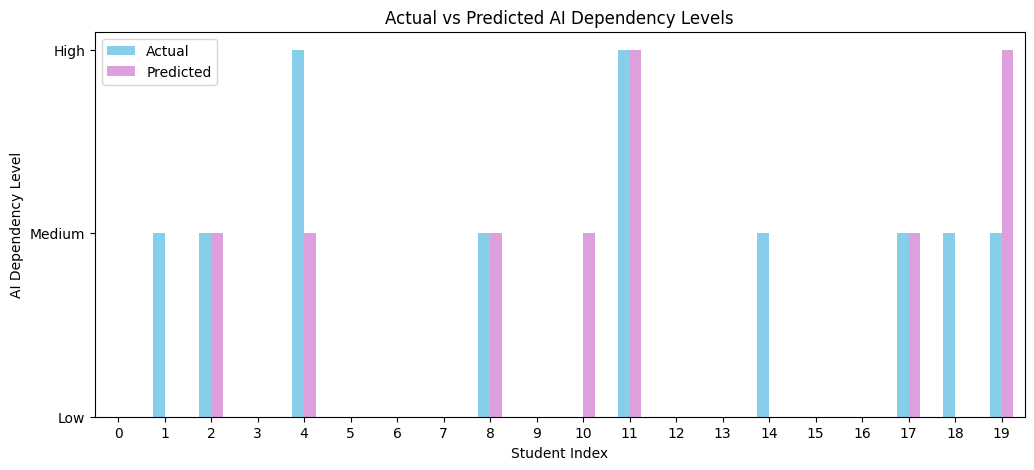

In [ ]:
comparison = pd.DataFrame({
    "Actual": y_test.values[:20],
    "Predicted": y_pred[:20]
})

class_mapping = {
    "Low": 0,
    "Medium": 1,
    "High": 2
}

comparison_numeric = comparison.replace(class_mapping)

comparison_numeric.plot(
    kind="bar",
    figsize=(12, 5),
    color=["skyblue", "plum"]
)

plt.title("Actual vs Predicted AI Dependency Levels")

plt.xlabel("Student Index")

plt.ylabel("AI Dependency Level")

plt.yticks(
    [0, 1, 2],
    ["Low", "Medium", "High"]
)

plt.xticks(rotation=0)

plt.legend()

plt.show()

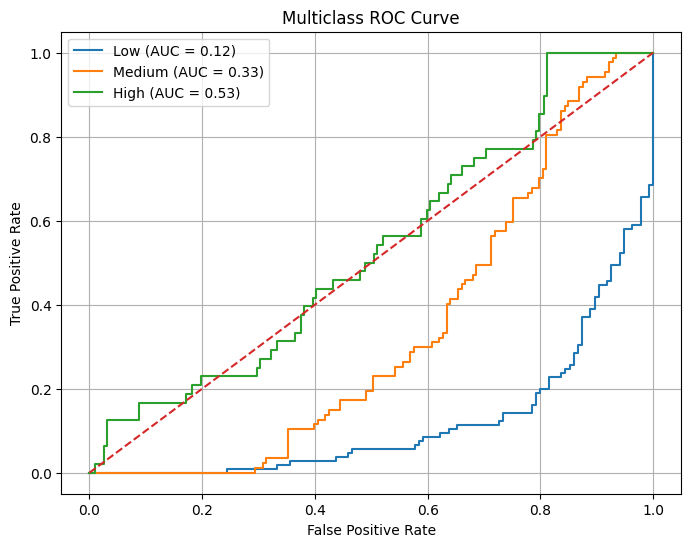

Overall ROC-AUC Score: 0.828


In [ ]:
y_prob = model.predict_proba(X_test)

classes = ["Low", "Medium", "High"]

y_test_binary = label_binarize(
    y_test,
    classes=classes
)

plt.figure(figsize=(8, 6))

for i, class_name in enumerate(classes):

    fpr, tpr, thresholds = roc_curve(
        y_test_binary[:, i],
        y_prob[:, i]
    )

    auc = roc_auc_score(
        y_test_binary[:, i],
        y_prob[:, i]
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC = {auc:.2f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("Multiclass ROC Curve")

plt.legend()

plt.grid()

plt.show()

print(
    "Overall ROC-AUC Score:",
    round(
        roc_auc_score(
            y_test,
            y_prob,
            multi_class="ovr",
            average="weighted"
        ),
        3
    )
)

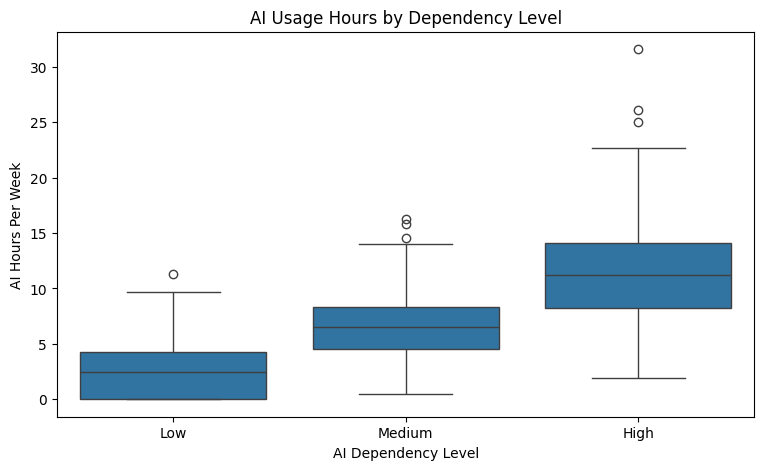

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="ai_dependency_level",
    y="ai_hours_per_week",
    order=["Low", "Medium", "High"]
)

plt.title("AI Usage Hours by Dependency Level")

plt.xlabel("AI Dependency Level")

plt.ylabel("AI Hours Per Week")

plt.show()

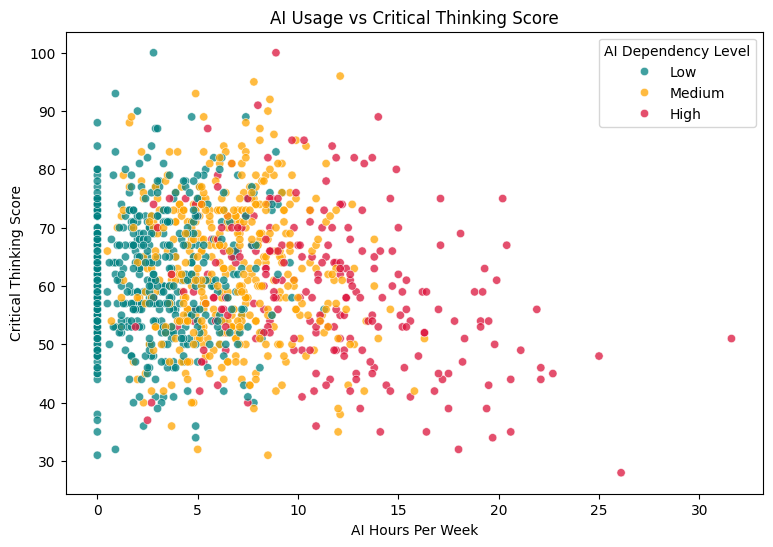

In [ ]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="ai_hours_per_week",
    y="critical_thinking_score",
    hue="ai_dependency_level",
    hue_order=["Low", "Medium", "High"],
    palette={
        "Low": "teal",
        "Medium": "orange",
        "High": "crimson"
    },
    alpha=0.75
)

plt.title("AI Usage vs Critical Thinking Score")

plt.xlabel("AI Hours Per Week")

plt.ylabel("Critical Thinking Score")

plt.legend(title="AI Dependency Level")

plt.show()

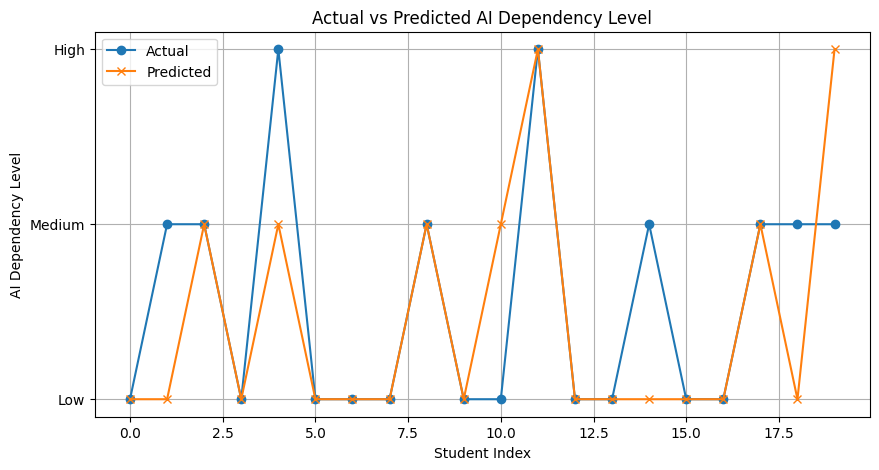

In [ ]:
comparison = pd.DataFrame({
    "Actual": y_test.values[:20],
    "Predicted": y_pred[:20]
})

plt.figure(figsize=(10, 5))

plt.plot(
    comparison.index,
    comparison["Actual"],
    marker="o",
    label="Actual"
)

plt.plot(
    comparison.index,
    comparison["Predicted"],
    marker="x",
    label="Predicted"
)

plt.title("Actual vs Predicted AI Dependency Level")

plt.xlabel("Student Index")

plt.ylabel("AI Dependency Level")

plt.legend()

plt.grid(True)

plt.show()

In [ ]:
import os
import zipfile
from google.colab import files

# Create visualization folder
os.makedirs("visualizations", exist_ok=True)

# 1. Confusion Matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Confusion Matrix")

plt.tight_layout()

plt.savefig(
    "visualizations/confusion_matrix.png",
    dpi=300
)

plt.close()


# 2. Model Performance
plt.figure(figsize=(8, 5))

plt.bar(
    metrics.keys(),
    metrics.values(),
    color=["skyblue", "lightgreen", "orange", "plum"]
)

plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Model Performance")

plt.tight_layout()

plt.savefig(
    "visualizations/model_performance.png",
    dpi=300
)

plt.close()


# 3. Box Plot
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="ai_dependency_level",
    y="ai_hours_per_week",
    order=["Low", "Medium", "High"]
)

plt.title("AI Usage Hours by Dependency Level")

plt.tight_layout()

plt.savefig(
    "visualizations/box_plot.png",
    dpi=300
)

plt.close()


# 4. Scatter Plot
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="ai_hours_per_week",
    y="critical_thinking_score",
    hue="ai_dependency_level",
    hue_order=["Low", "Medium", "High"]
)

plt.title("AI Usage vs Critical Thinking Score")

plt.tight_layout()

plt.savefig(
    "visualizations/scatter_plot.png",
    dpi=300
)

plt.close()


# 5. Actual vs Predicted
plt.figure(figsize=(10, 5))

plt.plot(
    comparison.index,
    comparison["Actual"],
    marker="o",
    label="Actual"
)

plt.plot(
    comparison.index,
    comparison["Predicted"],
    marker="x",
    label="Predicted"
)

plt.title("Actual vs Predicted AI Dependency Level")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "visualizations/actual_vs_predicted.png",
    dpi=300
)

plt.close()


# 6. ROC Curve
plt.figure(figsize=(8, 6))

for i, class_name in enumerate(classes):

    fpr, tpr, thresholds = roc_curve(
        y_test_binary[:, i],
        y_prob[:, i]
    )

    auc = roc_auc_score(
        y_test_binary[:, i],
        y_prob[:, i]
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC = {auc:.2f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curve")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "visualizations/roc_curve.png",
    dpi=300
)

plt.close()


# Create ZIP file
zip_filename = "campus_ai_visualizations.zip"

with zipfile.ZipFile(zip_filename, "w") as zip_file:

    for filename in os.listdir("visualizations"):

        zip_file.write(
            os.path.join("visualizations", filename),
            arcname=filename
        )

print("All visualizations saved successfully!")

files.download(zip_filename)

All visualizations saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>